In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.stats as scipy_stats
rng = np.random.default_rng(67)

# Задание 1

465663 -> Вариант 4

С помощью ММП найти оценку параметра $\theta$

$$
f_\theta(x)=\frac{3x^2}{\sqrt{2\pi}}\exp\left(-\frac{(\theta-x^3)^2}{2}\right) 
\qquad x\in\mathbb R \quad\theta\in\mathbb R
$$

Пусть

$$
Y=X^3
$$

Функция $x\mapsto x^3$ строго возрастает на $\mathbb R$ плотность $Y$ можно получить заменой переменной $y=x^3$

$$
\begin{aligned}
g_\theta(y)
&=f_\theta(\sqrt[3]{y})\left|\frac{d\sqrt[3]{y}}{dy}\right|\\
&=\frac{3(\sqrt[3]{y})^2}{\sqrt{2\pi}}\exp\left(-\frac{(\theta-y)^2}{2}\right)\frac{1}{3(\sqrt[3]{y})^2}\\
&=\frac{1}{\sqrt{2\pi}}\exp\left(-\frac{(y-\theta)^2}{2}\right)
\end{aligned}
$$

То есть

$$
\boxed{Y=X^3\sim\mathcal N(\theta;1)}
$$

$$
\boxed{F_\theta(x)=P(X\leq x)=P(Y\leq x^3)=\Phi(x^3-\theta) }
$$

где $\Phi$ это CDF стандартного нормального закона

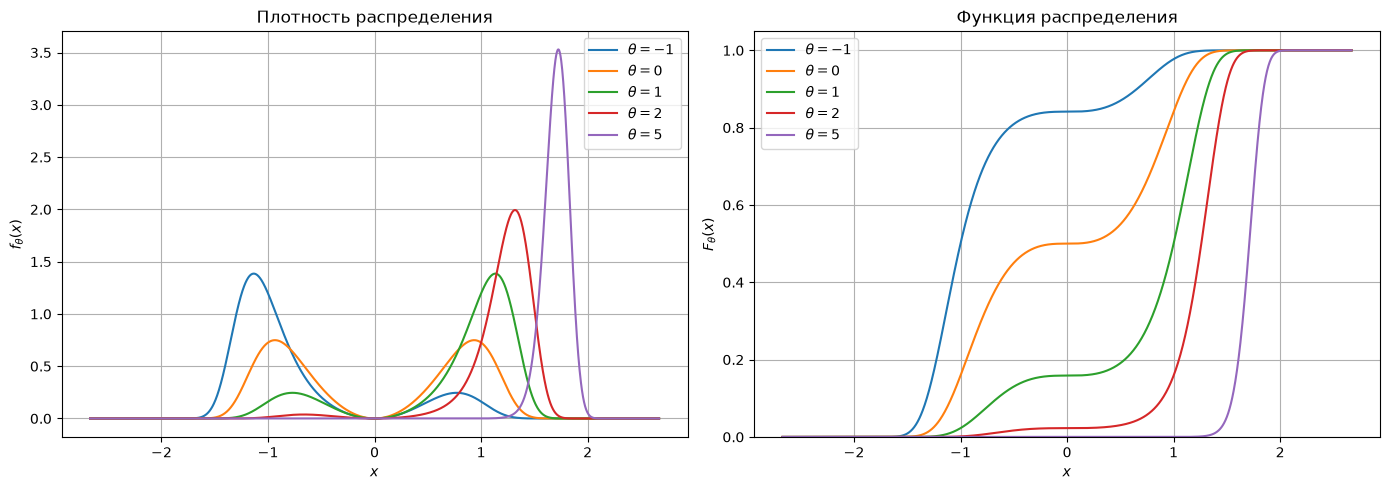

In [10]:
x_grid = np.linspace(-2.67, 2.67, 1670)
theta_values = [-1, 0, 1, 2, 5]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for theta_value in theta_values:
    f = 3 * x_grid**2 * scipy_stats.norm.pdf(x_grid**3 - theta_value)
    F = scipy_stats.norm.cdf(x_grid**3 - theta_value)

    axes[0].plot(x_grid, f, label=rf"$\theta={theta_value}$")
    axes[1].plot(x_grid, F, label=rf"$\theta={theta_value}$")

axes[0].set_title("Плотность распределения")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel(r"$f_\theta(x)$")
axes[0].grid()
axes[0].legend()

axes[1].set_title("Функция распределения")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel(r"$F_\theta(x)$")
axes[1].set_ylim(0, 1.05)
axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()

## Оценка максимального правдоподобия

Пусть $X_1,\ldots, X_n$ - iid выборка с плотностью $f_\theta(x)$

Функция правдоподобия

$$
L(\theta)=\prod_{i=1}^n f_\theta(X_i)
=\prod_{i=1}^n\frac{3X_i^2}{\sqrt{2\pi}}\exp\left(-\frac{(\theta-X_i^3)^2}{2}\right)
$$

$$
\ell(\theta)=\ln L(\theta)
=C-\frac12\sum_{i=1}^n(\theta-X_i^3)^2
$$

$$
\ell'(\theta)=-\sum_{i=1}^n(\theta-X_i^3)
=\sum_{i=1}^n X_i^3-n\theta 
$$

Это точка глобального максимума, так как

$$
\ell''(\theta)=-n<0
$$

$$
\ell'(\widehat\theta)=0
\quad\Longrightarrow\quad
\boxed{\widehat\theta_{\mathrm{ММП}}=\frac1n\sum_{i=1}^n X_i^3}
$$

## Свойства оценки

$$
Y_i=X_i^3\sim\mathcal N(\theta;1)
$$

$$
\mathbb E[Y_i]=\theta \qquad \operatorname{Var}(Y_i)=1
$$

$$
\widehat\theta=\overline Y_n=\frac1n\sum_{i=1}^nY_i
$$

### Смещение

$$
\mathbb E[\widehat\theta]
=\frac1n\sum_{i=1}^n\mathbb E[Y_i]
=\theta
$$

$$
\boxed{\operatorname{Bias}(\widehat\theta)=\mathbb E[\widehat\theta]-\theta=0}
$$

То есть оценка несмещённая

### Дисперсия

$$
\begin{aligned}
\operatorname{Var}(\widehat\theta)
=\operatorname{Var}\left(\frac1n\sum_{i=1}^nY_i\right)
=\frac1{n^2}\sum_{i=1}^n\operatorname{Var}(Y_i)
=\frac1n
\end{aligned}
$$

$$
\boxed{\operatorname{Var}(\widehat\theta)=\frac1n}
$$

### MSE

$$
\operatorname{MSE}(\widehat\theta)
=\mathbb E[(\widehat\theta-\theta)^2]
=\operatorname{Var}(\widehat\theta)+\operatorname{Bias}(\widehat\theta)^2
$$

$$
\boxed{\operatorname{MSE}(\widehat\theta)=\frac1n}
$$

### Состоятельность

Хотим

$$
\widehat\theta_n \xrightarrow[n\to\infty]{} \theta \xLeftrightarrow{}
P(|\widehat\theta-\theta|>\varepsilon)\xrightarrow[n\to\infty]{}0
$$

По неравенство Чебышёва

$$
P(|\widehat\theta-\theta|>\varepsilon)
\leq\frac{\operatorname{Var}(\widehat\theta)}{\varepsilon^2}
=\frac1{n\varepsilon^2}\xrightarrow[n\to\infty]{} 0
$$

$$
\boxed{\widehat\theta\xrightarrow{P}\theta}
$$

То есть оценка состоятельна

### Нормальность

$\widehat\theta$ это сумма iid нормальных случайных величин, поэтому

$$
\boxed{\widehat\theta\sim\mathcal N\left(\theta;\frac1n\right)}
$$

$$
\boxed{Z_n=\sqrt n(\widehat\theta-\theta)\sim\mathcal N(0;1)}
$$

То есть оценка нормальная

## Оптимальность

$$
f_\theta(x)=\frac{3x^2}{\sqrt{2\pi}}\exp\left(-\frac{(\theta-x^3)^2}{2}\right) 
$$

$$
\ln f_\theta(x)=\ln\frac{3x^2}{\sqrt{2\pi}}-\frac{(\theta-x^3)^2}{2}
$$

$$
\frac{\partial}{\partial\theta}\ln f_\theta(x)=x^3-\theta
$$

Так как
$$
\boxed{X^3\sim\mathcal N(\theta;1)}
$$

Информация Фишера для одного наблюдения

$$
\begin{aligned}
I(\theta)
=\mathbb E_\theta\left[
\left(\frac{\partial}{\partial\theta}\ln f_\theta(X)\right)^2
\right]
=\mathbb E_\theta\left[(X^3-\theta)^2\right]
=\mathbb E_\theta\left[(X^3-\mathbb E_\theta[X^3])^2\right]
=\operatorname{Var}_\theta(X^3)
=1
\end{aligned}
$$

Информация Фишера для $n$ наблюдений

$$
I_n(\theta)=nI(\theta)=n
$$

По неравенству Рао-Крамера

$$
\operatorname{Var}(\widehat\theta)\geq\frac{1}{I_n(\theta)}=\frac1n
$$

Ранее мы получили

$$
\operatorname{Var}(\widehat\theta)=\frac1n
$$

Таким образом оценка оптимальна среди среди несмещённых оценок


## Эксперимент

По условию $\theta=5$

Далее пользуемся тем что 
$$
Y\sim\mathcal N(\theta;1) \qquad X=\sqrt[3]{Y}
$$

Положим $\varepsilon=\frac{1} {10}$

$$
\begin{aligned}
P(|\widehat\theta-\theta|>\varepsilon)
=P(|Z_n|>\varepsilon\sqrt n)
=2\bigl(1-\Phi(\varepsilon\sqrt n)\bigr)
\end{aligned}
$$

После $M$ генераций выборки

$$
\widehat{\operatorname{Bias}}=\frac1M\sum_{j=1}^M(\widehat\theta_j-\theta) 
\qquad
\widehat{\operatorname{Var}}=\frac1{M-1}\sum_{j=1}^M(\widehat\theta_j-\overline{\widehat\theta})^2 
$$

$$
\widehat{\operatorname{MSE}}=\frac1M\sum_{j=1}^M(\widehat\theta_j-\theta)^2 
\qquad
\widehat p_\varepsilon=\frac1M\sum_{j=1}^M\mathbf1\{|\widehat\theta_j-\theta|>\varepsilon\}
$$

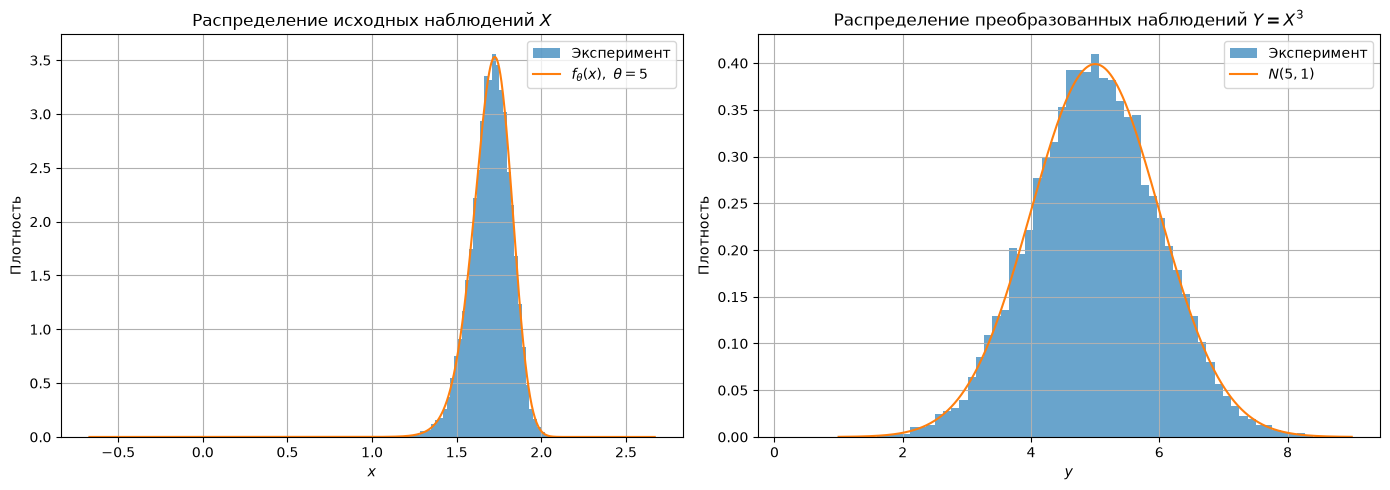

In [14]:
theta = 5.0

EXPERIMENTS_COUNT = 10_067
n_values = [10, 67, 567, 1067]
epsilon = 0.1

x_grid = np.linspace(-4, 4, 1067)

def model_sample(size):
    y = rng.normal(loc=theta, scale=1, size=size)
    return np.cbrt(y)

sample_x = model_sample(20_067)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_values = np.linspace(-0.67, 2.67, 1067)
f_values = 3 * x_values**2 * scipy_stats.norm.pdf(x_values**3 - theta)

axes[0].hist(sample_x, bins=67, density=True, alpha=0.67, label="Эксперимент")
axes[0].plot(x_values, f_values, label=r"$f_\theta(x),\ \theta=5$")
axes[0].set_title("Распределение исходных наблюдений $X$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("Плотность")
axes[0].grid()
axes[0].legend()

axes[1].hist(sample_x**3, bins=67, density=True, alpha=0.67, label="Эксперимент")
y_values = np.linspace(theta - 4, theta + 4, 1067)
axes[1].plot(y_values, scipy_stats.norm.pdf(y_values, loc=theta, scale=1), label=r"$N(5,1)$")
axes[1].set_title("Распределение преобразованных наблюдений $Y=X^3$")
axes[1].set_xlabel("$y$")
axes[1].set_ylabel("Плотность")
axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()

In [17]:
estimates_by_n = {}

for n in n_values:
    estimates = np.empty(EXPERIMENTS_COUNT)

    for start in range(0, EXPERIMENTS_COUNT, 1000):
        stop = min(start + 1000, EXPERIMENTS_COUNT)
        x = model_sample((stop - start, n))
        estimates[start:stop] = np.mean(x**3, axis=1)

    estimates_by_n[n] = estimates

statistics_estimates = []

for n in n_values:
    estimates = estimates_by_n[n]
    errors = estimates - theta

    statistics_estimates.append({
        "n": n,
        "Среднее оценки": estimates.mean(),
        "Смещение": errors.mean(),
        "Смещение (теория)": 0,
        "Дисперсия": estimates.var(ddof=1),
        "Дисперсия (теория)": 1 / n,
        "MSE": np.mean(errors**2),
        "MSE (теория)": 1 / n,
        "Доля |ошибка| > 0.1": np.mean(np.abs(errors) > epsilon),
        # scipy_stats.norm.sf(a) = 1 - PHI(a)
        "Доля |ошибка| > 0.1 (теория)": 2 * scipy_stats.norm.sf(epsilon * np.sqrt(n))
    })

df_estimates = pd.DataFrame(statistics_estimates)
df_estimates.round(5)

,n,Среднее оценки,Смещение,Смещение (теория),Дисперсия,Дисперсия (теория),MSE,MSE (теория),Доля |ошибка| > 0.1,Доля |ошибка| > 0.1 (теория)
0,10,4.99942,-0.00058,0,0.10113,0.10000,0.10112,0.10000,0.7459,0.75183
1,67,4.99952,-0.00048,0,0.01509,0.01493,0.01509,0.01493,0.4177,0.41305
2,567,4.99982,-0.00018,0,0.00172,0.00176,0.00172,0.00176,0.0153,0.01726
3,1067,5.00018,0.00018,0,0.00094,0.00094,0.00094,0.00094,0.0005,0.00109


## Проверка нормальности оценки

Для каждого $n$ построим гистограмму

$$
Z_n=\sqrt n(\widehat\theta-5)
$$

и сравним её с плотностью стандартного нормального распределения $\mathcal N(0;1)$

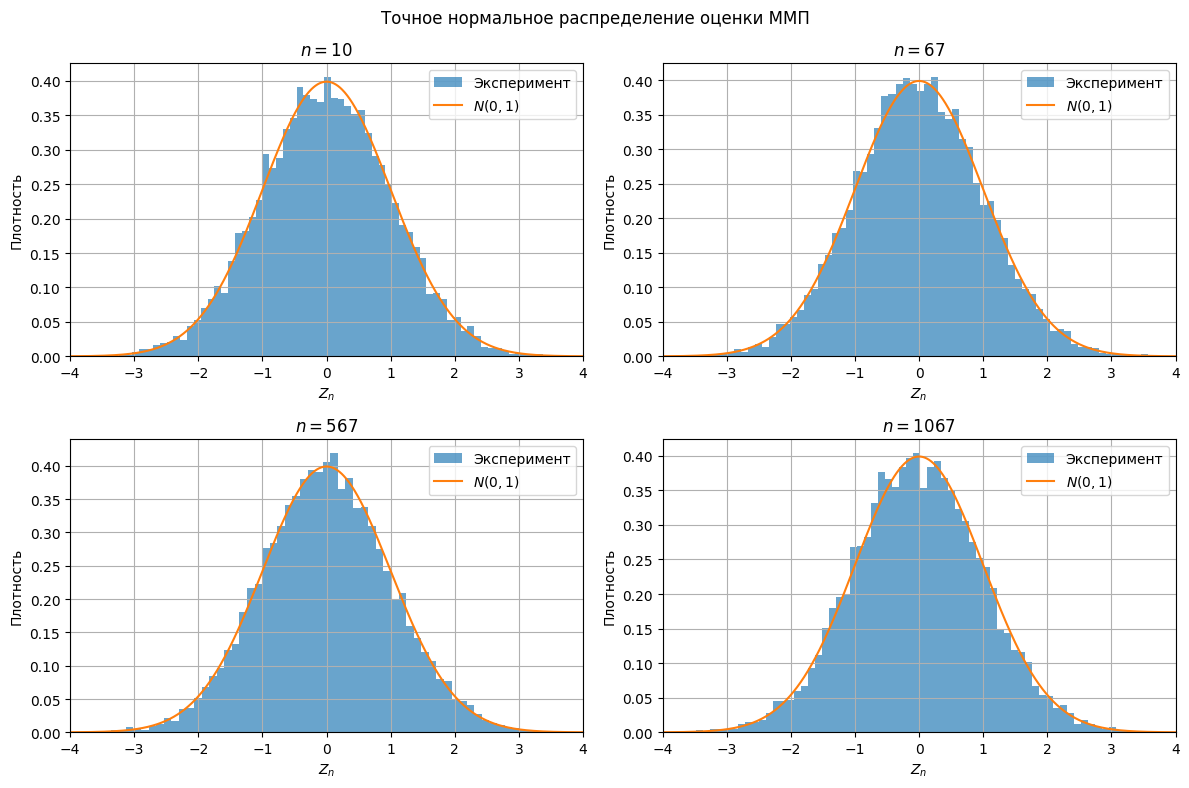

,n,Среднее,Дисперсия,Медиана
0,10,-0.00856,1.01395,-0.00751
1,67,-0.00254,0.98964,-0.01116
2,567,-0.00614,1.00623,-0.00844
3,1067,-0.01790,1.00648,-0.02777


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

statistics_normal = []

for ax, n in zip(axes.flat, n_values):
    z = np.sqrt(n) * (estimates_by_n[n] - theta)

    ax.hist(z, bins=67, density=True, alpha=0.67, label="Эксперимент")
    ax.plot(x_grid, scipy_stats.norm.pdf(x_grid), label="$N(0,1)$")

    ax.set_title(f"$n={n}$")
    ax.set_xlabel("$Z_n$")
    ax.set_ylabel("Плотность")
    ax.set_xlim(-4, 4)
    ax.grid()
    ax.legend()

    statistics_normal.append({
        "n": n,
        "Среднее": z.mean(),
        "Дисперсия": z.var(ddof=1),
        "Медиана": np.median(z)
    })

plt.suptitle("Точное нормальное распределение оценки ММП")
plt.tight_layout()
plt.show()

pd.DataFrame(statistics_normal).round(5)

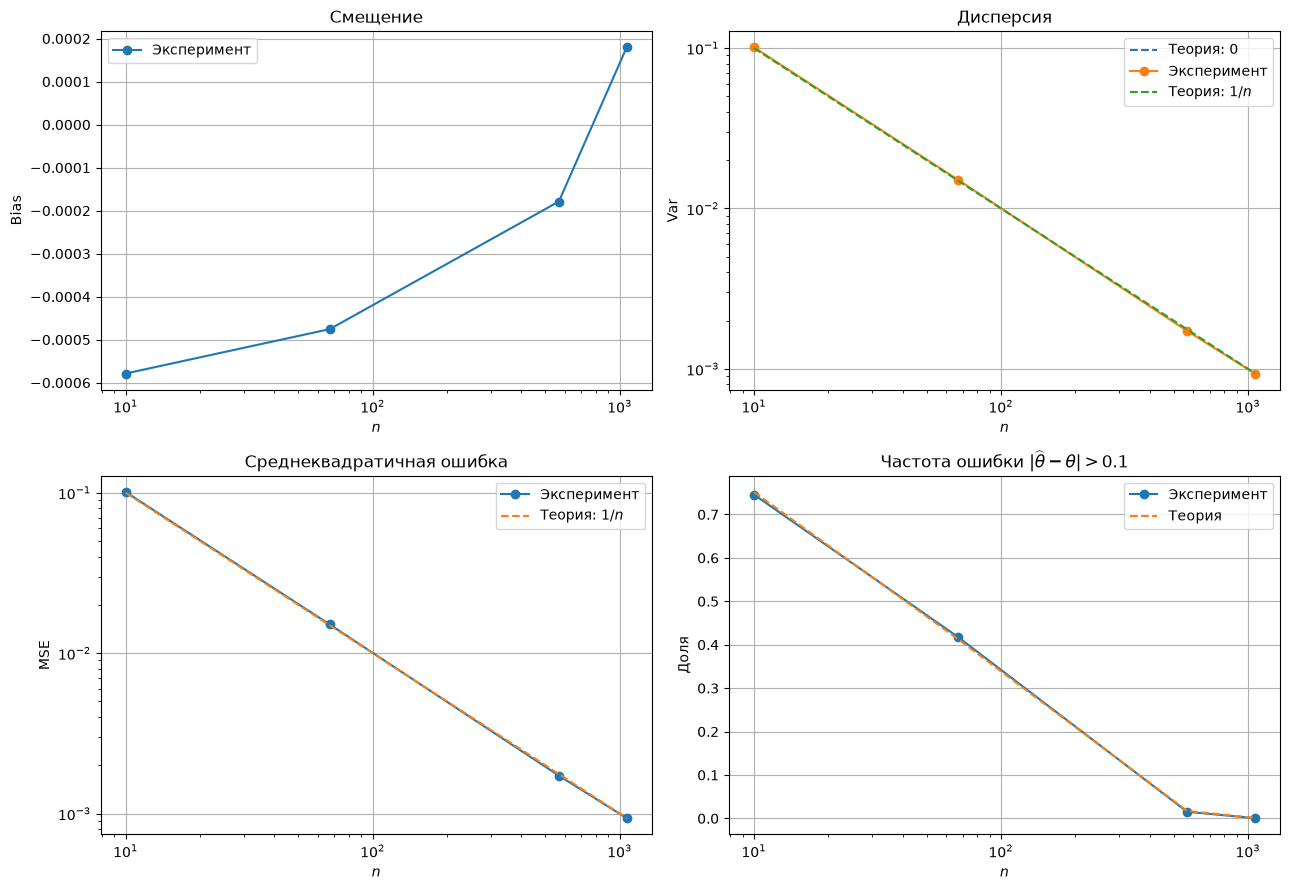

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

n_array = df_estimates["n"].to_numpy()

axes[0, 0].plot(n_array, df_estimates["Смещение"], "o-", label="Эксперимент")
axes[0, 1].plot(n_array, df_estimates["Смещение (теория)"], "--", label=r"Теория: $0$")
axes[0, 0].set_title("Смещение")
axes[0, 0].set_ylabel("Bias")

axes[0, 1].plot(n_array, df_estimates["Дисперсия"], "o-", label="Эксперимент")
axes[0, 1].plot(n_array, df_estimates["Дисперсия (теория)"], "--", label=r"Теория: $1/n$")
axes[0, 1].set_title("Дисперсия")
axes[0, 1].set_ylabel("Var")
axes[0, 1].set_yscale("log")

axes[1, 0].plot(n_array, df_estimates["MSE"], "o-", label="Эксперимент")
axes[1, 0].plot(n_array, df_estimates["MSE (теория)"], "--", label=r"Теория: $1/n$")
axes[1, 0].set_title("Среднеквадратичная ошибка")
axes[1, 0].set_ylabel("MSE")
axes[1, 0].set_yscale("log")

axes[1, 1].plot(n_array, df_estimates["Доля |ошибка| > 0.1"], "o-", label="Эксперимент")
axes[1, 1].plot(n_array, df_estimates["Доля |ошибка| > 0.1 (теория)"], "--", label="Теория")
axes[1, 1].set_title(r"Частота ошибки $|\widehat\theta-\theta|>0.1$")
axes[1, 1].set_ylabel("Доля")

for ax in axes.flat:
    ax.set_xlabel("$n$")
    ax.set_xscale("log")
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

## Вывод

Для распределения с плотностью

$$
f_\theta(x)=\frac{3x^2}{\sqrt{2\pi}}\exp\left(-\frac{(\theta-x^3)^2}{2}\right)
$$

Использовали $Y=X^3\sim\mathcal N(\theta;1)$ и получили оценку

$$
\boxed{\widehat\theta_{\mathrm{ММП}}=\frac1n\sum_{i=1}^n X_i^3}
$$

Со свойствами

$$
\boxed{
\operatorname{Bias}(\widehat\theta)=0 
\quad
\operatorname{Var}(\widehat\theta)=\frac1n 
\quad
\operatorname{MSE}(\widehat\theta)=\frac1n
}
$$

Оценка несмещённая, состоятельная и нормальная

# Задание 2 

465663 -> Вариант 1

Пусть

$$
X_1,\ldots, X_n\overset{iid}{\sim}\operatorname{Pois}(\theta)
$$

Априорное распределение параметра

$$
\theta\sim\Gamma(k;\lambda)
$$

Пусть
$$
X_1\ldots X_n\overset{iid}{\sim}\operatorname{Pois}(\theta)
$$

Пуассон

$$
P_\theta(X_i=x_i)=\frac{\theta^{x_i}e^{-\theta}}{x_i!}
$$

Пусть

$$
S=\sum_{i=1}^n X_i
$$

Функция правдоподобия

$$
\begin{aligned}
L(\theta)
=\prod_{i=1}^n P_\theta(X_i=x_i)
=\prod_{i=1}^n\frac{\theta^{x_i}e^{-\theta}}{x_i!}
=\frac{\theta^{\sum_{i=1}^n x_i}e^{-n\theta}}{\prod_{i=1}^n x_i!}
=\frac{\theta^S e^{-n\theta}}{\prod_{i=1}^n x_i!}
\end{aligned}
$$

### Априорное распределение

$$
\theta\sim\Gamma(k;\lambda)
$$

Априорная плотность при $\theta>0$

$$
\boxed{
\pi(\theta)=
\frac{\lambda^k}{\Gamma(k)}
\theta^{k-1}e^{-\lambda\theta}
}
$$

Где

$$
\Gamma(k)=\int_0^\infty t^{k-1}e^{-t}\,dt
$$

$$
\mathbb E\theta=\frac{k}{\lambda}
$$

$$
\operatorname{Var}(\theta)=\frac{k}{\lambda^2}
$$

### Апостериорное распределение

По формуле Байеса

$$
\boxed{
\pi(\theta\mid X)=
\frac{L(\theta)\pi(\theta)}
{\displaystyle\int_0^\infty L(t)\pi(t)\,dt}
}
$$

$$
\begin{aligned}
L(\theta)\pi(\theta)
=
\frac{\theta^S e^{-n\theta}}{\prod_{i=1}^n x_i!}
\cdot
\frac{\lambda^k}{\Gamma(k)}
\theta^{k-1}e^{-\lambda\theta}
=
\frac{\lambda^k}{\Gamma(k)\prod_{i=1}^n x_i!}
\theta^{S+k-1}e^{-(n+\lambda)\theta}
\end{aligned}
$$

$$
\begin{aligned}
\int_0^\infty L(t)\pi(t)\,dt
&=
\frac{\lambda^k}{\Gamma(k)\prod_{i=1}^n x_i!}
\int_0^\infty t^{S+k-1}e^{-(n+\lambda)t}\,dt
\end{aligned}
$$

Замена

$$
u=(n+\lambda)t
$$

Тогда

$$
t=\frac{u}{n+\lambda}
\qquad
dt=\frac{du}{n+\lambda}
$$

Получаем

$$
\begin{aligned}
&\int_0^\infty t^{S+k-1}e^{-(n+\lambda)t}\,dt\\
&=
\int_0^\infty
\left(\frac{u}{n+\lambda}\right)^{S+k-1}
e^{-u}\frac{du}{n+\lambda}\\
&=
\frac{1}{(n+\lambda)^{S+k}}
\int_0^\infty u^{S+k-1}e^{-u}\,du\\
&=
\frac{\Gamma(S+k)}{(n+\lambda)^{S+k}}
\end{aligned}
$$


Таким образом нормировочная константа равна

$$
\boxed{
\int_0^\infty L(t)\pi(t)\,dt
=
\frac{\lambda^k\Gamma(S+k)}
{\Gamma(k)(n+\lambda)^{S+k}\prod_{i=1}^n x_i!}
}
$$

$$
\pi(\theta\mid X)=
\frac{
\displaystyle
\frac{\lambda^k}{\Gamma(k)\prod_{i=1}^n x_i!}
\theta^{S+k-1}e^{-(n+\lambda)\theta}
}{
\displaystyle
\frac{\lambda^k\Gamma(S+k)}
{\Gamma(k)(n+\lambda)^{S+k}\prod_{i=1}^n x_i!}
}
$$

$$
\boxed{
\pi(\theta\mid X)=
\frac{(n+\lambda)^{S+k}}{\Gamma(S+k)}
\theta^{S+k-1}e^{-(n+\lambda)\theta}
}
$$

Сравним с плотностью гамма распределения

$$
f(t)=\frac{b^a}{\Gamma(a)}t^{a-1}e^{-bt}
$$

Заметим, что равенство достигается при

$$
a=k+S
\qquad
b=\lambda+n
$$

Поэтому

$$
\boxed{
\theta\mid X\sim\Gamma(k+S;\lambda+n)
}
$$

### Сопряжённость

Сопряжённость означает что априорное и апостериорное распределения принадлежат одному семейству

У нас

$$
\underbrace{\Gamma(k;\lambda)}_{\text{Априорное}}
\quad\longrightarrow\quad
\underbrace{\Gamma(k+S;\lambda+n)}_{\text{Апостериорное}}
$$

После получения выборки изменяются только параметры гамма распределения

Поэтому гамма распределение является сопряжённым априорным распределением для параметра распределения Пуассона

### Характеристики апостериорного распределения

Математическое ожидание

$$
\boxed{
\mathbb E[\theta\mid X]
=
\frac{k+S}{\lambda+n}
}
$$

Дисперсия
$$
\boxed{
\operatorname{Var}(\theta\mid X)
\frac{k+S}{(\lambda+n)^2}
}
$$

### Наши параметры

По условию

$$
k=1
\qquad
\lambda=1
$$

Поэтому априорное распределение имеет вид (распределение Эрлана порядка 1)

$$
\theta\sim\Gamma(1;1)
$$

А после наблюдения выборки

$$
\boxed{
\theta\mid X\sim\Gamma(1+S;1+n)
}
$$

$$
\boxed{
\mathbb E[\theta\mid X]=\frac{1+S}{1+n}
}
$$

$$
\boxed{
\operatorname{Var}(\theta\mid X)=\frac{1+S}{(1+n)^2}
}
$$


## Байесовская оценка при квадратичной функции потерь

Функция потерь - это функция $\mathcal L(t;\theta)$ которая показывает величину ущерба при выборе оценки $t$ когда истинное значение параметра равно $\theta$

При квадратичной функции потерь

$$
\boxed{
\mathcal L_2(t;\theta)=(t-\theta)^2
}
$$

$$
\theta\mid X\sim\Gamma(a;b)
$$

Вычислим апостериорный риск -  математическое ожидание потерь относительно апостериорного распределения

$$
\boxed{
\rho_2(t\mid X)
=
\mathbb E[(t-\theta)^2\mid X]
}
$$

$$
\rho_2(t\mid X)
=
\int_0^\infty
(t-\theta)^2\pi(\theta\mid X)\,d\theta
$$

Здесь $t$ является выбираемой нами оценкой а интегрирование происходит по неизвестному параметру $\theta$

Тогда Байесовская оценка - это значение $t$ минимизирующее апостериорный риск

$$
\widehat\theta_{B2}
=
\underset{t>0}{\arg\min}\;\rho_2(t\mid X)
$$

### Минимизация апостериорного риска

Пусть

$$
m=\mathbb E[\theta\mid X]
$$

$$
t-\theta=(t-m)+(m-\theta)
$$

$$
(t-\theta)^2
=
(t-m)^2
+
2(t-m)(m-\theta)
+
(m-\theta)^2
$$

$$
\begin{aligned}
\rho_2(t\mid X)
&=
\mathbb E[(t-\theta)^2\mid X]\\
&=
(t-m)^2
+
2(t-m)\mathbb E[m-\theta\mid X]\\
&\quad+
\mathbb E[(m-\theta)^2\mid X]
\end{aligned}
$$

По определению $m$

$$
\mathbb E[m-\theta\mid X]
=
m-\mathbb E[\theta\mid X]
=
0
$$

Последнее слагаемое является апостериорной дисперсией

$$
\mathbb E[(m-\theta)^2\mid X]
=
\operatorname{Var}(\theta\mid X)
$$

Получаем

$$
\boxed{
\rho_2(t\mid X)
=
(t-m)^2
+
\operatorname{Var}(\theta\mid X)
}
$$

Второе слагаемое не зависит от $t$

Первое слагаемое неотрицательно и обращается в ноль только при $t=m$

Следовательно минимум достигается при

$$
t=m=\mathbb E[\theta\mid X]
$$

Таким образом при квадратичной функции потерь байесовской оценкой является апостериорное математическое ожидание

$$
\boxed{
\widehat\theta_{B2}
=
\mathbb E[\theta\mid X]
}
$$

У нас

$$
\boxed{
\widehat\theta_{B2}=\frac{k+S}{\lambda+n}=\frac{1+S}{1+n}
}
$$

### Минимальное значение апостериорного риска

$$
\begin{aligned}
\rho_2(\widehat\theta_{B2}\mid X)
&=
(m-m)^2+\operatorname{Var}(\theta\mid X)\\
&=
\operatorname{Var}(\theta\mid X)
\end{aligned}
$$

Следовательно

$$
\boxed{
\min_{t>0}\rho_2(t\mid X)
=
\frac{k+S}{(\lambda+n)^2}
}
$$


## Байесовская оценка при абсолютной функции потерь

Абсолютная функция потерь

$$
\boxed{
\mathcal L_1(t;\theta)=|t-\theta|
}
$$

$$
\boxed{
\rho_1(t\mid X)
=
\mathbb E[|t-\theta|\mid X]
}
$$

$$
\rho_1(t\mid X)
=
\int_0^\infty
|t-\theta|\pi(\theta\mid X)\,d\theta
$$

Найдём значение $t$ минимизирующее этот интеграл

$$
\widehat\theta_{B1}
=
\underset{t>0}{\arg\min}\;\rho_1(t\mid X)
$$

### Минимизация апостериорного риска

$$
\begin{aligned}
\rho_1(t\mid X)
&=
\int_0^t(t-\theta)\pi(\theta\mid X)\,d\theta\\
&\quad+
\int_t^\infty(\theta-t)\pi(\theta\mid X)\,d\theta
\end{aligned}
$$

Для первого интеграла

$$
\begin{aligned}
&\frac{d}{dt}
\int_0^t(t-\theta)\pi(\theta\mid X)\,d\theta\\
&=
(t-t)\pi(t\mid X)
+
\int_0^t\pi(\theta\mid X)\,d\theta\\
&=
\int_0^t\pi(\theta\mid X)\,d\theta
\end{aligned}
$$

Для второго интеграла

$$
\begin{aligned}
&\frac{d}{dt}
\int_t^\infty(\theta-t)\pi(\theta\mid X)\,d\theta\\
&=
-(t-t)\pi(t\mid X)
-
\int_t^\infty\pi(\theta\mid X)\,d\theta\\
&=
-\int_t^\infty\pi(\theta\mid X)\,d\theta
\end{aligned}
$$

Итого

$$
\rho_1'(t\mid X)
=
\int_0^t\pi(\theta\mid X)\,d\theta
-
\int_t^\infty\pi(\theta\mid X)\,d\theta
$$

Обозначим функцию апостериорного распределения через $F$

$$
F(t\mid X)
=
P(\theta\le t\mid X)
=
\int_0^t\pi(\theta\mid X)\,d\theta
$$

Поскольку интеграл всей плотности равен единице

$$
\int_t^\infty\pi(\theta\mid X)\,d\theta
=
1-F(t\mid X)
$$

Следовательно

$$
\begin{aligned}
\rho_1'(t\mid X)
&=
F(t\mid X)-(1-F(t\mid X))\\
&=
2F(t\mid X)-1
\end{aligned}
$$

Получаем

$$
\boxed{
\rho_1'(t\mid X)
=
2F(t\mid X)-1
}
$$

Найдём стационарную точку

$$
\rho_1'(t\mid X)=0
$$

$$
2F(t\mid X)-1=0
$$

Отсюда

$$
\boxed{
F(t\mid X)=\frac12
}
$$

Это условие определяет медиану непрерывного распределения


$$
\rho_1''(t\mid X)
=
2\frac{d}{dt}F(t\mid X)
$$

По определению плотности

$$
\frac{d}{dt}F(t\mid X)=\pi(t\mid X)
$$

Следовательно

$$
\boxed{
\rho_1''(t\mid X)=2\pi(t\mid X)>0
}
$$

Апостериорная плотность гамма распределения положительна при $t>0$

Поэтому апостериорный риск строго выпуклый и найденная стационарная точка является единственным глобальным минимумом

Таким образом при абсолютной функции потерь байесовской оценкой является апостериорная медиана

$$
\boxed{
\widehat\theta_{B1}
=
\operatorname{Med}(\theta\mid X)
}
$$

У нас

$$
\boxed{
\widehat\theta_{B1}
=
F_{\Gamma(k+S;\lambda+n)}^{-1}
\left(\frac12\right)
}
$$

$$
\boxed{
\widehat\theta_{B1}
=
F_{\Gamma(1+S;1+n)}^{-1}
\left(\frac12\right)
}
$$


## Байесовская оценка при функции потерь 0-1

### Проблема непрерывности параметра

Стандартная функция потерь 0-1 определяется следующим образом

$$
\boxed{
\mathcal L_{01}(t;\theta)
=
\begin{cases}
0, t=\theta\\
1, t\ne\theta
\end{cases}
}
$$

Она равна нулю только при точном совпадении оценки с истинным параметром

Апостериорный риск

$$
\rho_{01}(t\mid X)
=
\mathbb E[\mathcal L_{01}(t;\theta)\mid X]
$$

Поскольку математическое ожидание индикатора события равно вероятности этого события

$$
\rho_{01}(t\mid X)
=
P(\theta\ne t\mid X)
$$

Однако наш параметр имеет непрерывное апостериорное распределение

Поэтому для любого фиксированного $t$

$$
P(\theta=t\mid X)=0
$$

Следовательно

$$
\boxed{
\rho_{01}(t\mid X)=1
}
$$

Получается что ожидаемая потеря одинакова для любого значения оценки

Поэтому обычная функция потерь 0-1 не позволяет выделить единственную оптимальную оценку непрерывного параметра

### Введение допустимой погрешности

Чтобы учесть непрерывность параметра введём допуск $\varepsilon>0$

Определим модифицированную функцию потерь

$$
\boxed{
\mathcal L_\varepsilon(t;\theta)
=
\begin{cases}
0 & |t-\theta|\le\varepsilon\\
1 & |t-\theta|>\varepsilon
\end{cases}
}
$$

Теперь потеря равна нулю если оценка отличается от истинного параметра не более чем на $\varepsilon$

Апостериорный риск

$$
\begin{aligned}
\rho_\varepsilon(t\mid X)
&=
\mathbb E[\mathcal L_\varepsilon(t;\theta)\mid X]\\
&=
P(|t-\theta|>\varepsilon\mid X)
\end{aligned}
$$

По правилу дополнения вероятностей

$$
\rho_\varepsilon(t\mid X)
=
1-P(|t-\theta|\le\varepsilon\mid X)
$$

Преобразуем событие

$$
|t-\theta|\le\varepsilon
\iff
t-\varepsilon\le\theta\le t+\varepsilon
$$

Поэтому

$$
\rho_\varepsilon(t\mid X)
=
1-P(t-\varepsilon\le\theta\le t+\varepsilon\mid X)
$$

Так как $\theta>0$ получаем

$$
\boxed{
\rho_\varepsilon(t\mid X)
=
1-\int_{\max(0;t-\varepsilon)}^{t+\varepsilon}
\pi(\theta\mid X)\,d\theta
}
$$

Обозначим функцию апостериорного распределения через $F$

$$
F(t\mid X)=P(\theta\le t\mid X)
$$

Тогда

$$
\boxed{
\rho_\varepsilon(t\mid X)
=
1-F(t+\varepsilon\mid X)
+
F(\max(0;t-\varepsilon)\mid X)
}
$$

### Минимизация апостериорного риска

Байесовская оценка должна минимизировать $\rho_\varepsilon(t\mid X)$

$$
\widehat\theta_{B\varepsilon}
\in
\underset{t\ge0}{\arg\min}\;
\rho_\varepsilon(t\mid X)
$$

Поскольку единица не зависит от $t$ минимизация риска эквивалентна максимизации вероятности попадания параметра в интервал

$$
[t-\varepsilon;t+\varepsilon]
$$

Следовательно

$$
\boxed{
\widehat\theta_{B\varepsilon}
\in
\underset{t\ge0}{\arg\max}\;
\left[
F(t+\varepsilon\mid X)
-
F(\max(0;t-\varepsilon)\mid X)
\right]
}
$$

Таким образом мы ищем центр интервала длины $2\varepsilon$ содержащего максимальную апостериорную вероятность

### Применение к гамма распределению

Мы получили

$$
\theta\mid X\sim\Gamma(a;b)
$$

Его плотность

$$
f(t)=
\frac{b^a}{\Gamma(a)}
t^{a-1}e^{-bt}
$$

Рассмотрим отдельно случаи $a>1$ и $a\le1$

### Случай $a>1$

При $a>1$ гамма плотность сначала возрастает а затем убывает

Для $0\le t\le\varepsilon$ вероятность интервала равна $F(t+\varepsilon)$ и возрастает с увеличением $t$

При $t>\varepsilon$ вероятность интервала

$$
Q(t)=F(t+\varepsilon)-F(t-\varepsilon)
$$

Найдём её производную

$$
Q'(t)=f(t+\varepsilon)-f(t-\varepsilon)
$$

В стационарной точке

$$
Q'(t)=0
$$

Поэтому

$$
\boxed{
f(t+\varepsilon)=f(t-\varepsilon)
}
$$

Подставим гамма плотность

$$
\begin{aligned}
&\frac{b^a}{\Gamma(a)}
(t+\varepsilon)^{a-1}e^{-b(t+\varepsilon)}\\
&=
\frac{b^a}{\Gamma(a)}
(t-\varepsilon)^{a-1}e^{-b(t-\varepsilon)}
\end{aligned}
$$

Сокращаем одинаковые множители

$$
(t+\varepsilon)^{a-1}e^{-b(t+\varepsilon)}
=
(t-\varepsilon)^{a-1}e^{-b(t-\varepsilon)}
$$

Переносим экспоненты

$$
\left(
\frac{t+\varepsilon}{t-\varepsilon}
\right)^{a-1}
=
e^{2b\varepsilon}
$$

Логарифмируем

$$
(a-1)
\ln\left(
\frac{t+\varepsilon}{t-\varepsilon}
\right)
=
2b\varepsilon
$$

Разделим на $a-1$

$$
\ln\left(
\frac{t+\varepsilon}{t-\varepsilon}
\right)
=
\frac{2b\varepsilon}{a-1}
$$

Потенцируем

$$
\frac{t+\varepsilon}{t-\varepsilon}
=
\exp\left(
\frac{2b\varepsilon}{a-1}
\right)
$$

Для краткости обозначим

$$
q=
\exp\left(
\frac{2b\varepsilon}{a-1}
\right)
$$

Тогда

$$
t+\varepsilon=q(t-\varepsilon)
$$

Раскрываем скобки

$$
t+\varepsilon=qt-q\varepsilon
$$

Переносим слагаемые

$$
t(q-1)=\varepsilon(q+1)
$$

Получаем

$$
t=\varepsilon\frac{q+1}{q-1}
$$

Подставляем выражение для $q$

$$
t=
\varepsilon
\frac{
\exp\left(\frac{2b\varepsilon}{a-1}\right)+1
}{
\exp\left(\frac{2b\varepsilon}{a-1}\right)-1
}
$$

Используем определение гиперболического тангенса

$$
\tanh z=\frac{e^{2z}-1}{e^{2z}+1}
$$

Следовательно

$$
\boxed{
\widehat\theta_{B\varepsilon}
=
\frac{\varepsilon}
{\tanh\left(\frac{b\varepsilon}{a-1}\right)}
}
$$

При $a>1$ гамма плотность строго логарифмически вогнута

Уравнение $f(t+\varepsilon)=f(t-\varepsilon)$ имеет единственное решение при $t>\varepsilon$

До этой точки вероятность $Q(t)$ возрастает а после убывает

Поэтому найденная точка является глобальным максимумом вероятности попадания в интервал

### Случай $a\le1$

При $a\le1$ гамма плотность убывает на положительной полуоси

Следовательно интервал длины $2\varepsilon$ содержащий наибольшую вероятность начинается от нуля

Оптимальный интервал

$$
[0;2\varepsilon]
$$

Его центр

$$
\boxed{
\widehat\theta_{B\varepsilon}=\varepsilon
}
$$

### Итоговая оценка для фиксированного допуска

Объединяя оба случая получаем

$$
\boxed{
\widehat\theta_{B\varepsilon}
=
\begin{cases}
\displaystyle
\frac{\varepsilon}
{\tanh\left(\frac{b\varepsilon}{a-1}\right)}
& a>1\\[8pt]
\varepsilon
& a\le1
\end{cases}
}
$$

В нашей задаче

$$
a=k+S
\qquad
b=\lambda+n
$$

Поэтому

$$
\boxed{
\widehat\theta_{B\varepsilon}
=
\begin{cases}
\displaystyle
\frac{\varepsilon}
{\tanh\left(\frac{(\lambda+n)\varepsilon}{k+S-1}\right)}
& k+S>1\\[8pt]
\varepsilon
& k+S\le1
\end{cases}
}
$$

### Предельный случай при малом допуске

Теперь исследуем поведение оценки при $\varepsilon\to0$

Для $a>1$ используем известный предел

$$
\lim_{z\to0}\frac{\tanh z}{z}=1
$$

Следовательно при малых $z$

$$
\tanh z\sim z
$$

Подставим

$$
z=\frac{b\varepsilon}{a-1}
$$

Тогда

$$
\begin{aligned}
\lim_{\varepsilon\to0}
\widehat\theta_{B\varepsilon}
&=
\lim_{\varepsilon\to0}
\frac{\varepsilon}
{\tanh\left(\frac{b\varepsilon}{a-1}\right)}\\
&=
\frac{a-1}{b}
\end{aligned}
$$

При $a\le1$

$$
\lim_{\varepsilon\to0}
\widehat\theta_{B\varepsilon}
=
\lim_{\varepsilon\to0}\varepsilon
=
0
$$

Таким образом

$$
\boxed{
\lim_{\varepsilon\to0}\widehat\theta_{B\varepsilon}
=
\frac{\max(a-1;0)}{b}
}
$$

### Оценка MAP

Предельная оценка соответствует точке максимума апостериорной плотности и называется MAP

$$
\widehat\theta_{\mathrm{MAP}}
\in
\underset{t\ge0}{\arg\max}\;\pi(t\mid X)
$$

Для $a>1$ максимум гамма плотности находится внутри положительной полуоси

Для $a=1$ максимум достигается на границе $t=0$ после её включения в пространство решений

Для $a<1$ плотность неограниченно возрастает при приближении к нулю и имеет граничную моду

Следовательно MAP в расширенном пространстве решений определяется формулой

$$
\boxed{
\widehat\theta_{\mathrm{MAP}}
=
\frac{\max(a-1;0)}{b}
}
$$

Подставляя апостериорные параметры получаем

$$
\boxed{
\widehat\theta_{\mathrm{MAP}}
=
\frac{\max(k+S-1;0)}{\lambda+n}
}
$$

При заданных значениях $k=1$ и $\lambda=1$

$$
\boxed{
\widehat\theta_{\mathrm{MAP}}
=
\frac{S}{n+1}
}
$$

При $S=0$ получаем граничное значение $0$ которое формально не принадлежит пространству $\theta>0$

Поэтому это значение следует понимать как предельное решение или как оценку в расширенном пространстве $t\ge0$

### Вывод

Обычная функция потерь 0-1 не позволяет выделить оптимальную оценку непрерывного параметра поскольку её апостериорный риск равен единице для любого решения

После введения допуска $\varepsilon$ оптимальная оценка становится центром интервала максимальной апостериорной вероятности

В пределе при $\varepsilon\to0$ получаем апостериорную моду MAP

При фиксированном положительном $\varepsilon$ оценка MAP и оптимальная оценка для потери с допуском в общем случае различаются



## Оценка максимального правдоподобия

Рассмотрим выборку из распределения Пуассона

$$
X_1\ldots X_n\overset{iid}{\sim}\operatorname{Pois}(\theta)
$$

Обозначим сумму наблюдений

$$
S=\sum_{i=1}^n X_i
$$

Ранее мы получили функцию правдоподобия

$$
L(\theta)=
\frac{\theta^S e^{-n\theta}}{\prod_{i=1}^n X_i!}
$$

Оценка максимального правдоподобия является значением параметра при котором функция правдоподобия достигает максимума

Для удобства прологарифмируем функцию

$$
\begin{aligned}
\ell(\theta)
&=\ln L(\theta)\\
&=S\ln\theta-n\theta-\sum_{i=1}^n\ln(X_i!)\\
&=S\ln\theta-n\theta+C
\end{aligned}
$$

Здесь $C$ обозначает слагаемое не зависящее от параметра $\theta$

Найдём первую производную

$$
\ell'(\theta)=\frac{S}{\theta}-n
$$

При $S>0$ приравняем её нулю

$$
\frac{S}{\theta}-n=0
$$

Отсюда

$$
\theta=\frac{S}{n}
$$

Проверим вторую производную

$$
\ell''(\theta)=-\frac{S}{\theta^2}<0
$$

При $S>0$ функция строго вогнута на $\theta>0$

Следовательно найденная стационарная точка является единственным глобальным максимумом

Таким образом

$$
\boxed{
\widehat\theta_{\text{ММП}}
=
\frac{S}{n}
=
\overline X
}
$$

При $S=0$ функция правдоподобия имеет вид

$$
L(\theta)=e^{-n\theta}
$$

Она убывает по $\theta$ и её супремум достигается при $\theta\to0$

Если разрешить граничное значение $\theta=0$ то оценка ММП существует и при $S=0$

В дальнейшем используем пространство решений $\theta\ge0$

Таким образом для всех возможных выборок

$$
\boxed{
\widehat\theta_{\text{ММП}}=\overline X
}
$$



## Смещение и среднеквадратичная ошибка

Рассмотрим частотные характеристики байесовской оценки при квадратичной потере и оценки максимального правдоподобия

Здесь истинный параметр $\theta$ считается фиксированным

Поскольку сумма независимых пуассоновских величин имеет распределение Пуассона

$$
S=\sum_{i=1}^nX_i\sim\operatorname{Pois}(n\theta)
$$

Следовательно

$$
\boxed{
\mathbb E_\theta S=n\theta
\qquad
\operatorname{Var}_\theta(S)=n\theta
}
$$

### Байесовская оценка при квадратичной потере

Ранее получили

$$
\widehat\theta_{B2}=\frac{S+k}{n+\lambda}
$$

Смещением оценки называется разность между её математическим ожиданием и истинным параметром

$$
\operatorname{Bias}_\theta(\widehat\theta_{B2})
=
\mathbb E_\theta\widehat\theta_{B2}-\theta
$$

Найдём математическое ожидание

$$
\begin{aligned}
\mathbb E_\theta\widehat\theta_{B2}
&=\mathbb E_\theta\frac{S+k}{n+\lambda}\\
&=\frac{\mathbb E_\theta S+k}{n+\lambda}\\
&=\frac{n\theta+k}{n+\lambda}
\end{aligned}
$$

Следовательно

$$
\begin{aligned}
\operatorname{Bias}_\theta(\widehat\theta_{B2})
&=\frac{n\theta+k}{n+\lambda}-\theta\\
&=\frac{n\theta+k-n\theta-\lambda\theta}{n+\lambda}
\end{aligned}
$$

Получаем

$$
\boxed{
\operatorname{Bias}_\theta(\widehat\theta_{B2})
=
\frac{k-\lambda\theta}{n+\lambda}
}
$$

Теперь найдём дисперсию

$$
\begin{aligned}
\operatorname{Var}_\theta(\widehat\theta_{B2})
&=\operatorname{Var}_\theta\left(\frac{S+k}{n+\lambda}\right)\\
&=\frac{\operatorname{Var}_\theta(S)}{(n+\lambda)^2}\\
&=\frac{n\theta}{(n+\lambda)^2}
\end{aligned}
$$

Среднеквадратичная ошибка определяется как

$$
\operatorname{MSE}_\theta(\widehat\theta)
=
\mathbb E_\theta(\widehat\theta-\theta)^2
$$

Используем разложение

$$
\operatorname{MSE}_\theta(\widehat\theta)
=
\operatorname{Var}_\theta(\widehat\theta)
+
\operatorname{Bias}_\theta^2(\widehat\theta)
$$

Подставляем найденные выражения

$$
\boxed{
\operatorname{MSE}_\theta(\widehat\theta_{B2})
=
\frac{n\theta+(k-\lambda\theta)^2}{(n+\lambda)^2}
}
$$

### Оценка максимального правдоподобия

Имеем

$$
\widehat\theta_{\text{ММП}}=\frac{S}{n}
$$

Математическое ожидание

$$
\mathbb E_\theta\widehat\theta_{\text{ММП}}
=
\frac{\mathbb E_\theta S}{n}
=
\theta
$$

Поэтому ММП является несмещённой оценкой

$$
\boxed{
\operatorname{Bias}_\theta(\widehat\theta_{\text{ММП}})=0
}
$$

Дисперсия

$$
\operatorname{Var}_\theta(\widehat\theta_{\text{ММП}})
=
\frac{\operatorname{Var}_\theta(S)}{n^2}
=
\frac{\theta}{n}
$$

Поскольку смещение равно нулю

$$
\boxed{
\operatorname{MSE}_\theta(\widehat\theta_{\text{ММП}})
=
\frac{\theta}{n}
}
$$


## Байесовский риск и сравнение с ММП

Ранее мы вычислили MSE оценок при фиксированном истинном параметре $\theta$

Теперь рассмотрим байесовский риск который учитывает априорное распределение параметра

При квадратичной функции потерь частотный риск оценки $\delta(X)$ равен

$$
R_2(\theta;\delta)
=
\mathbb E_\theta(\delta(X)-\theta)^2
$$

Байесовский риск определяется как математическое ожидание частотного риска относительно априорного распределения

$$
\boxed{
r(\delta)
=
\mathbb E_{\theta\sim\pi}R_2(\theta;\delta)
}
$$

По определению математического ожидания

$$
r(\delta)
=
\int_0^\infty R_2(\theta;\delta)\pi(\theta)\,d\theta
$$

Таким образом частотный риск показывает качество оценки при конкретном $\theta$ а байесовский риск усредняет качество по всем возможным значениям параметра с учётом априорного распределения

### Байесовский риск апостериорного среднего

При квадратичной потере оптимальной байесовской оценкой является апостериорное математическое ожидание

$$
\widehat\theta_{B2}=\mathbb E[\theta\mid X]
$$

Ранее мы доказали что минимальный апостериорный квадратичный риск равен апостериорной дисперсии

$$
\rho_2(\widehat\theta_{B2}\mid X)
=
\operatorname{Var}(\theta\mid X)
$$

По формуле полного математического ожидания

$$
r(\widehat\theta_{B2})
=
\mathbb E_X\operatorname{Var}(\theta\mid X)
$$

Мы знаем что

$$
\theta\mid X\sim\Gamma(k+S;\lambda+n)
$$

Поэтому

$$
\operatorname{Var}(\theta\mid X)
=
\frac{k+S}{(\lambda+n)^2}
$$

Следовательно

$$
\begin{aligned}
r(\widehat\theta_{B2})
&=
\mathbb E_X\frac{k+S}{(\lambda+n)^2}\\
&=
\frac{k+\mathbb E_XS}{(\lambda+n)^2}
\end{aligned}
$$

Вычислим математическое ожидание суммы по совместному распределению параметра и выборки

$$
\begin{aligned}
\mathbb E_XS
&=\mathbb E_\theta[\mathbb E(S\mid\theta)]\\
&=\mathbb E_\theta[n\theta]\\
&=n\frac{k}{\lambda}
\end{aligned}
$$

Подставляем результат

$$
\begin{aligned}
r(\widehat\theta_{B2})
&=
\frac{k+nk/\lambda}{(\lambda+n)^2}\\
&=
\frac{k(\lambda+n)}{\lambda(\lambda+n)^2}
\end{aligned}
$$

Получаем

$$
\boxed{
r(\widehat\theta_{B2})
=
\frac{k}{\lambda(\lambda+n)}
}
$$

### Байесовский риск ММП

Для оценки максимального правдоподобия

$$
\operatorname{MSE}_\theta(\widehat\theta_{\text{ММП}})
=
\frac{\theta}{n}
$$

Поэтому байесовский риск

$$
\begin{aligned}
r(\widehat\theta_{\text{ММП}})
&=\mathbb E_{\theta\sim\pi}\frac{\theta}{n}\\
&=\frac1n\mathbb E_\theta\theta\\
&=\frac{k}{\lambda n}
\end{aligned}
$$

Следовательно

$$
\boxed{
r(\widehat\theta_{\text{ММП}})
=
\frac{k}{\lambda n}
}
$$

### Сравнение рисков

Найдём разность

$$
\begin{aligned}
r(\widehat\theta_{\text{ММП}})
-
r(\widehat\theta_{B2})
&=
\frac{k}{\lambda n}
-
\frac{k}{\lambda(\lambda+n)}\\
&=
\frac{k}{n(\lambda+n)}
\end{aligned}
$$

При $k>0$ и $\lambda>0$ эта разность положительна

Следовательно

$$
\boxed{
r(\widehat\theta_{B2})
<
r(\widehat\theta_{\text{ММП}})
}
$$

При заданных параметрах $k=\lambda=1$

$$
\boxed{
r(\widehat\theta_{B2})=\frac1{n+1}
}
$$

$$
\boxed{
r(\widehat\theta_{\text{ММП}})=\frac1n
}
$$

### Вывод

Байесовское среднее минимизирует интегральный квадратичный риск при заданном априорном распределении

Поэтому его байесовский риск меньше риска ММП при любом конечном $n$

Это не означает что байесовская оценка обязательно лучше ММП при каждом фиксированном значении истинного параметра

При увеличении объёма выборки различие между байесовскими рисками уменьшается



## Минимаксность

### Виды статистического риска

Пусть $\delta(X)$ обозначает оценку параметра $\theta$ а $\mathcal L(t;\theta)$ является функцией потерь

**Апостериорный риск** показывает ожидаемую потерю при выборе значения $t$ после наблюдения выборки $X$

$$
\boxed{
\rho(t\mid X)
=
\mathbb E[\mathcal L(t;\theta)\mid X]
}
$$

Усреднение производится по апостериорному распределению параметра при фиксированной выборке

**Частотный риск** показывает ожидаемую потерю оценки $\delta(X)$ при фиксированном истинном параметре $\theta$

$$
\boxed{
R(\theta;\delta)
=
\mathbb E_\theta[\mathcal L(\delta(X);\theta)]
}
$$

Здесь усреднение производится по всем возможным выборкам при данном $\theta$

Для квадратичной функции потерь частотный риск совпадает с MSE

**Байесовский риск** получается дополнительным усреднением частотного риска по априорному распределению параметра

$$
\boxed{
r(\delta)
=
\mathbb E_{\theta\sim\pi}R(\theta;\delta)
}
$$

$$
r(\delta)
=
\int_\Theta R(\theta;\delta)\pi(\theta)\,d\theta
$$

Байесовская оценка минимизирует этот средний риск для выбранного априорного распределения

### Минимаксный подход

В отличие от байесовского подхода минимаксный подход не использует усреднение по априорному распределению

Для каждой оценки рассматривается её максимальный возможный риск

$$
R_{\max}(\delta)
=
\sup_{\theta\in\Theta}R(\theta;\delta)
$$

**Минимаксной** называется оценка минимизирующая наихудший риск

$$
\boxed{
\delta^*
\in
\underset{\delta}{\arg\min}
\sup_{\theta\in\Theta}R(\theta;\delta)
}
$$

Таким образом байесовский подход минимизирует среднюю потерю по априорному распределению

Минимаксный подход минимизирует потерю в наиболее неблагоприятном случае

### Особенности нашей задачи

Мы рассматриваем распределение Пуассона с неограниченным пространством параметров

$$
X_i\sim\operatorname{Pois}(\theta)
\qquad
\Theta=(0;\infty)
$$

**Квадратичная функция потерь**

Для ММП

$$
R_2(\theta;\widehat\theta_{\text{ММП}})
=
\frac{\theta}{n}
$$

Следовательно

$$
\sup_{\theta>0}R_2(\theta;\widehat\theta_{\text{ММП}})
=
\infty
$$

Однако этого недостаточно для вывода о минимаксном риске поскольку необходимо рассмотреть все возможные оценки

Для гамма априорного распределения минимальный байесовский квадратичный риск равен

$$
r(\delta_B)=\frac{k}{\lambda(\lambda+n)}
$$

Максимальный частотный риск любой оценки не меньше её байесовского риска

Поэтому при $k=1$

$$
\sup_{\theta>0}R_2(\theta;\delta)
\ge
\frac{1}{\lambda(\lambda+n)}
$$

Это верно для любой оценки $\delta$ и любого $\lambda>0$

При $\lambda\to0$ правая часть неограниченно возрастает

Следовательно

$$
\boxed{
\inf_\delta\sup_{\theta>0}R_2(\theta;\delta)
=
\infty
}
$$

**Абсолютная функция потерь**

Аналогично при неограниченном параметре невозможно обеспечить ограниченный максимальный абсолютный риск

$$
\boxed{
\inf_\delta\sup_{\theta>0}
\mathbb E_\theta|\delta(X)-\theta|
=
\infty
}
$$

Интуитивно это связано с тем что при увеличении $\theta$ растёт абсолютный разброс пуассоновских наблюдений

**Функция потерь 0-1 с фиксированным допуском**

Для $\varepsilon>0$ риск равен вероятности большой ошибки

$$
R_\varepsilon(\theta;\delta)
=
P_\theta(|\delta(X)-\theta|>\varepsilon)
$$

Этот риск всегда ограничен единицей

Но при фиксированном $n$ и сколь угодно больших $\theta$ невозможно гарантировать попадание оценки в интервал фиксированной ширины $2\varepsilon$

Для любой оценки

$$
\sup_{\theta>0}R_\varepsilon(\theta;\delta)=1
$$

Следовательно

$$
\boxed{
\inf_\delta\sup_{\theta>0}R_\varepsilon(\theta;\delta)
=
1
}
$$

## Эксперимент

По условию

$$
k=1\qquad\lambda=1
$$

Проверим три значения истинного параметра

$$
\theta\in\left\{\frac15, \;1, \;5\right\}
$$


Все рассматриваемые оценки зависят от выборки только через 
$$
S=\sum_{i=1}^n X_i
$$

$$
S\sim\operatorname{Pois}(n\theta)
$$

Сравним смещение MSE среднюю абсолютную ошибку MAE и вероятность ошибки больше выбранного допуска

$$
\varepsilon=\frac1{10}
$$


In [29]:
prior_k = 1.0
prior_rate = 1.0

theta_values = [0.2, 1.0, 5.0]
epsilon = 0.1

def poisson_estimates(sums, n, eps=epsilon):
    a = prior_k + sums
    b = prior_rate + n
    
    mle = sums / n
    
    posterior_mean = a / b
    
    posterior_median = scipy_stats.gamma.ppf(0.5, a=a, scale=1 / b)
    
    posterior_mode = np.maximum(a - 1, 0) / b
    
    posterior_tolerance = np.where(
        a > 1,
        eps / np.tanh(b * eps / np.maximum(a - 1, 1e-12)),
        eps,
    )
    
    return {
        "ММП": mle,
        "Байес среднее": posterior_mean,
        "Байес медиана": posterior_median,
        "MAP": posterior_mode,
        "Байес 0–1": posterior_tolerance,
    }

## Априорная и апостериорная плотности на одной выборке

Для наглядности сгенерируем одну выборку из $\operatorname{Pois}(1)$

Построим априорную и апостериорную плотности и отметим полученные оценки

Рост объёма выборки приводит к концентрации апостериорного распределения вокруг параметра

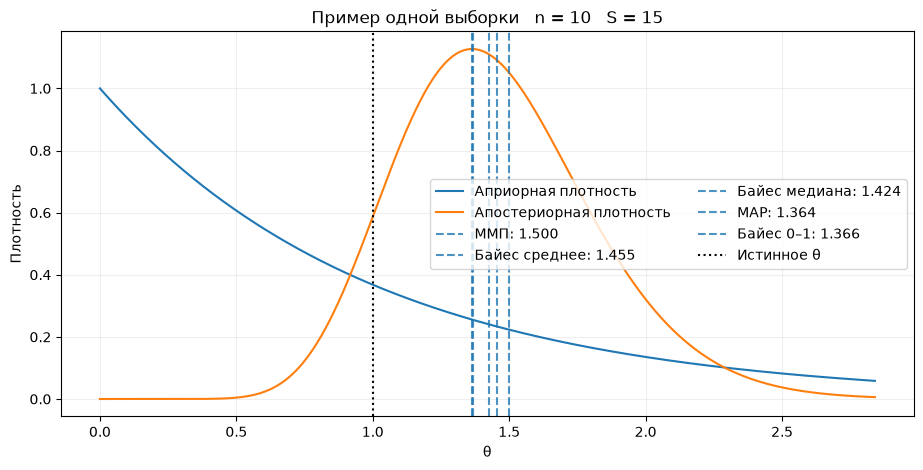

In [27]:
theta_demo = 1.0
n_demo = 10

sample_demo = rng.poisson(lam=theta_demo, size=n_demo)
s_demo = sample_demo.sum()

demo_a = prior_k + s_demo
demo_b = prior_rate + n_demo
demo_estimates = poisson_estimates(np.array([s_demo]), n_demo)

plot_right = max(2.5, scipy_stats.gamma.ppf(0.999, a=demo_a, scale=1 / demo_b))
posterior_grid = np.linspace(0.0, plot_right, 967)

plt.figure(figsize=(11, 5))
plt.plot(posterior_grid, scipy_stats.gamma.pdf(posterior_grid, a=prior_k, scale=1 / prior_rate), label="Априорная плотность")
plt.plot(posterior_grid, scipy_stats.gamma.pdf(posterior_grid, a=demo_a, scale=1 / demo_b), label="Апостериорная плотность")

for name, values in demo_estimates.items():
    plt.axvline(values[0], linestyle="--", alpha=0.8, label=f"{name}: {values[0]:.3f}")
    
plt.axvline(theta_demo, color="black", linestyle=":", label="Истинное θ")
plt.title(f"Пример одной выборки   n = {n_demo}   S = {s_demo}")
plt.xlabel("θ")
plt.ylabel("Плотность")
plt.grid(alpha=0.2)
plt.legend(ncol=2)
plt.show()

## Результаты многократного моделирования

Для каждой оценки $\delta$ находим ошибки

$$
e_j=\delta_j-\theta
$$

Эмпирические показатели

$$
\widehat{\operatorname{Bias}}=\frac1M\sum_{j=1}^Me_j
$$

$$
\widehat{\operatorname{MSE}}=\frac1M\sum_{j=1}^Me_j^2
$$

$$
\widehat{\operatorname{MAE}}=\frac1M\sum_{j=1}^M|e_j|
$$

$$
\widehat R_{\varepsilon}=\frac1M\sum_{j=1}^M\mathbf1\{|e_j|>\varepsilon\}
$$

Для квадратичной потери сравним экспериментальную MSE с её точным теоретическим значением

In [32]:
results = []

for theta_true in theta_values:
    for n in n_values:
        sample_sums = rng.poisson(lam=n * theta_true, size=EXPERIMENTS_COUNT)
        current = poisson_estimates(sample_sums, n)
        for name, values in current.items():
            errors = values - theta_true
            theory_mse = np.nan
            theory_bias = np.nan
            if name == "ММП":
                theory_mse = theta_true / n
                theory_bias = 0.0
            elif name == "Байес среднее":
                theory_bias = (prior_k - prior_rate * theta_true) / (n + prior_rate)
                theory_mse = (
                    n * theta_true + (prior_k - prior_rate * theta_true) ** 2
                ) / (n + prior_rate) ** 2
            results.append({
                "θ": theta_true,
                "n": n,
                "Оценка": name,
                "Смещение": errors.mean(),
                "MSE": np.mean(errors ** 2),
                "MAE": np.mean(np.abs(errors)),
                "P(|ошибка| > ε)": np.mean(np.abs(errors) > epsilon),
                "Теор смещение": theory_bias,
                "Теор MSE": theory_mse,
            })

df_results = pd.DataFrame(results)
df_results.round(5).head(15)

,θ,n,Оценка,Смещение,MSE,MAE,P(|ошибка| > ε),Теор смещение,Теор MSE
0,0.2,10,ММП,0.00149,0.02008,0.10802,0.27734,0.00000,0.02000
1,0.2,10,Байес среднее,0.07408,0.02208,0.11259,0.45595,0.07273,0.02182
2,0.2,10,Байес медиана,0.04471,0.01846,0.10632,0.45595,NaN,NaN
3,0.2,10,MAP,-0.01683,0.01688,0.10458,0.54674,NaN,NaN
4,0.2,10,Байес 0–1,0.01380,0.01199,0.08069,0.14572,NaN,NaN
5,0.2,67,ММП,-0.00029,0.00303,0.04400,0.05662,0.00000,0.00299
6,0.2,67,Байес среднее,0.01147,0.00308,0.04384,0.06715,0.01176,0.00304
7,0.2,67,Байес медиана,0.00659,0.00299,0.04312,0.08016,NaN,NaN
8,0.2,67,MAP,-0.00323,0.00296,0.04354,0.05662,NaN,NaN
9,0.2,67,Байес 0–1,0.01475,0.00264,0.04023,0.05811,NaN,NaN


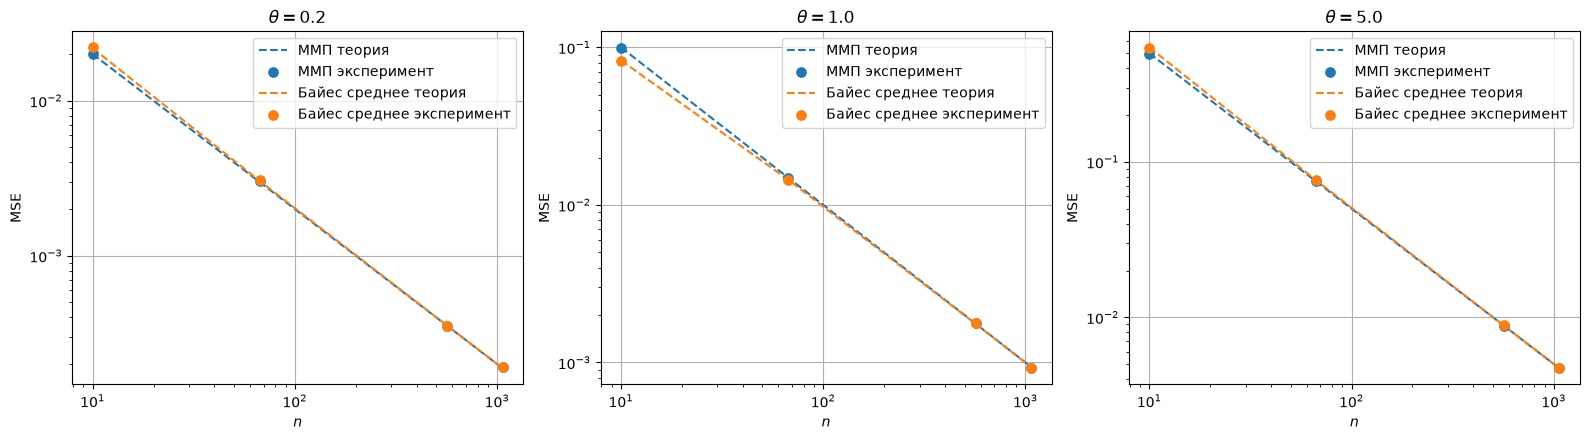

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, theta_true in zip(axes, theta_values):
    subset = df_results[df_results["θ"] == theta_true]

    for name in ["ММП", "Байес среднее"]:
        one = subset[subset["Оценка"] == name].sort_values("n")

        line, = ax.plot(
            one["n"],
            one["Теор MSE"],
            "--",
            label=f"{name} теория"
        )

        ax.scatter(
            one["n"],
            one["MSE"],
            color=line.get_color(),
            s=45,
            zorder=3,
            label=f"{name} эксперимент"
        )

    ax.set_title(rf"$\theta={theta_true}$")
    ax.set_xlabel("$n$")
    ax.set_ylabel("MSE")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()


In [12]:
df_theory_check = df_results_2[
    df_results_2["Оценка"].isin(["ММП", "Байес среднее"])
][["θ", "n", "Оценка", "Смещение", "Теор смещение", "MSE", "Теор MSE"]]

df_theory_check.round(5)

,θ,n,Оценка,Смещение,Теор смещение,MSE,Теор MSE
0,0.2,10,ММП,-0.00107,0.00000,0.02055,0.02000
1,0.2,10,Байес среднее,0.07175,0.07273,0.02213,0.02182
5,0.2,67,ММП,0.00022,0.00000,0.00292,0.00299
6,0.2,67,Байес среднее,0.01198,0.01176,0.00298,0.00304
10,0.2,567,ММП,-0.00008,0.00000,0.00035,0.00035
11,0.2,567,Байес среднее,0.00133,0.00141,0.00035,0.00035
15,0.2,1067,ММП,-0.00000,0.00000,0.00019,0.00019
16,0.2,1067,Байес среднее,0.00075,0.00075,0.00019,0.00019
20,1.0,10,ММП,0.00217,0.00000,0.10073,0.10000
21,1.0,10,Байес среднее,0.00197,0.00000,0.08325,0.08264


## Зависимость ошибок от объёма выборки

Для каждого истинного значения $\theta$ сравним оценки по трём функциям потерь

Чем ниже кривая тем лучше оценка при фиксированном значении параметра и выбранной потере

В частности апостериорное среднее оптимально по байесовскому квадратичному риску

Апостериорная медиана оптимальна по байесовскому абсолютному риску

Оценка с допуском оптимальна по апостериорной вероятности превышения этого допуска

Сравнение при фиксированном параметре не обязано сохранять этот порядок

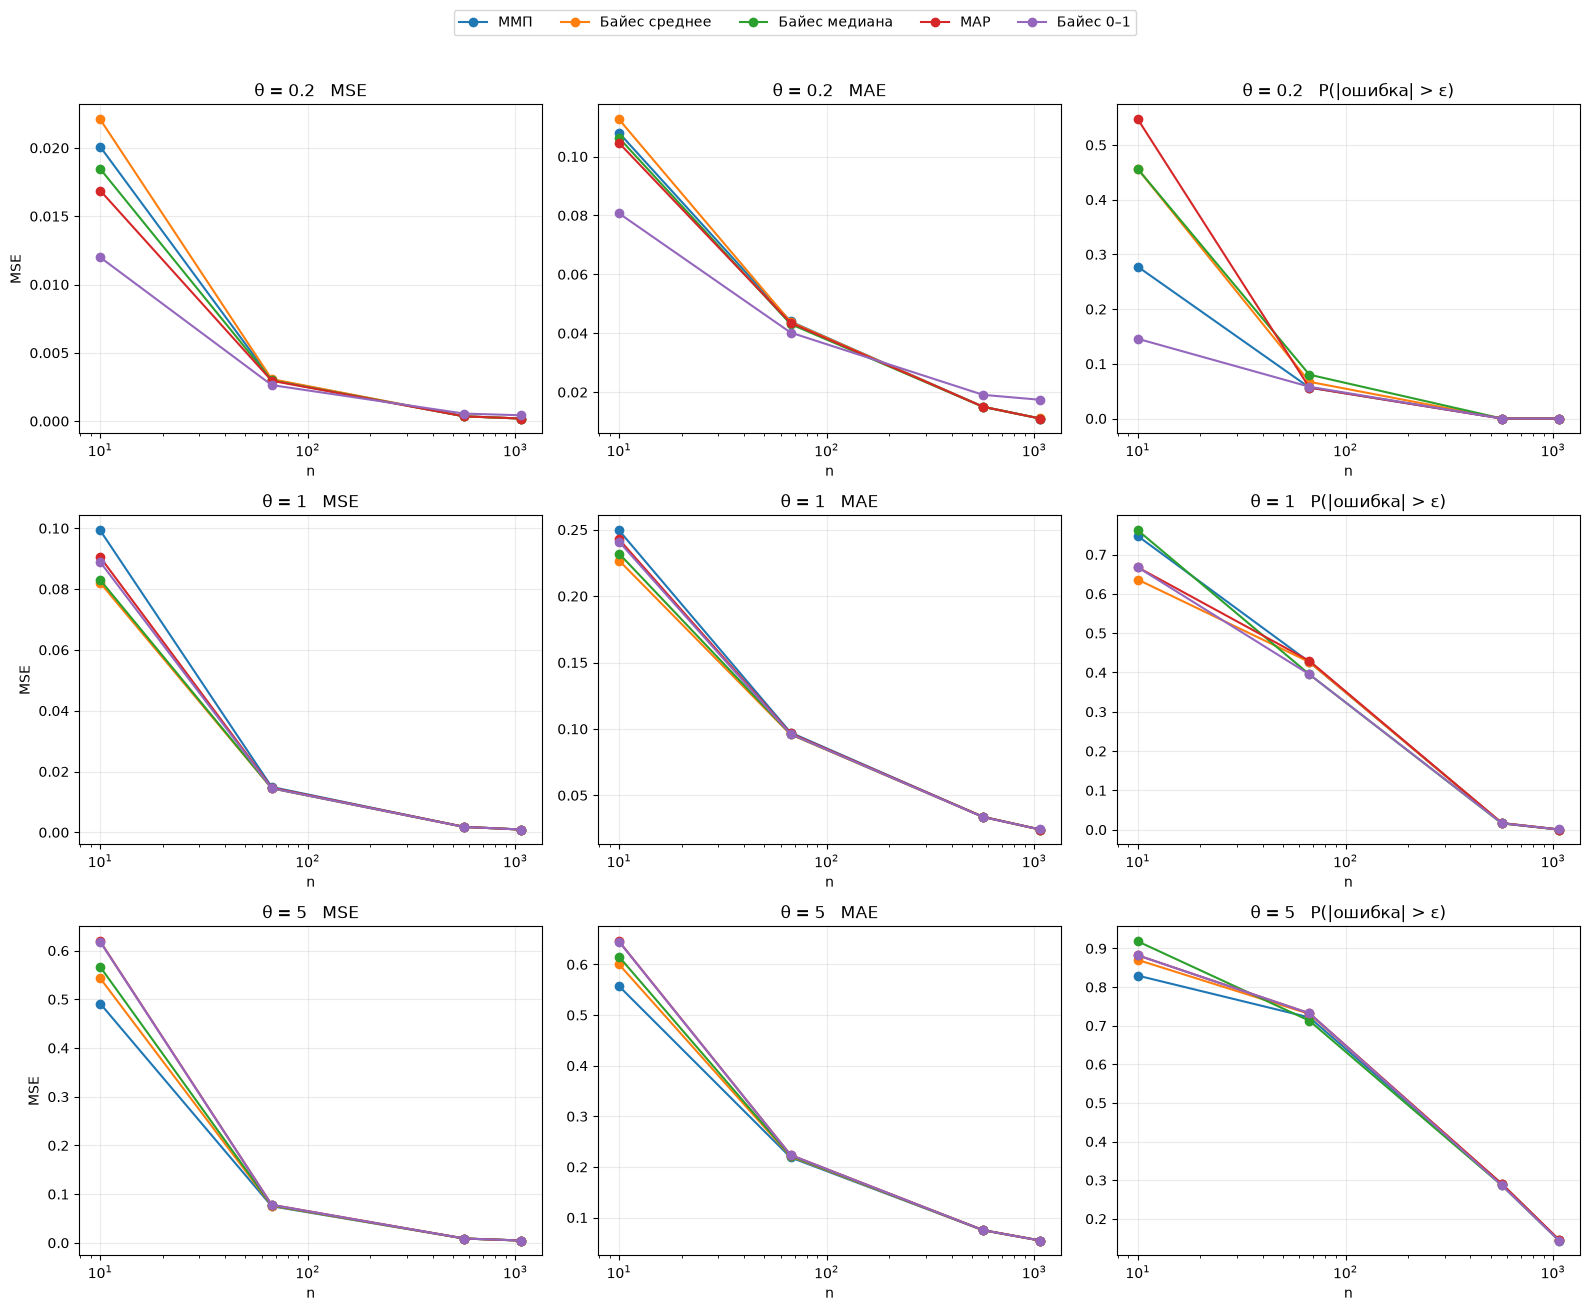

In [34]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
metrics = ["MSE", "MAE", "P(|ошибка| > ε)"]

for row, theta_true in enumerate(theta_values):
    for col, metric in enumerate(metrics):
        ax = axes[row, col]
        subset = df_results[df_results["θ"] == theta_true]
        for name in ["ММП", "Байес среднее", "Байес медиана", "MAP", "Байес 0–1"]:
            one = subset[subset["Оценка"] == name]
            ax.plot(one["n"], one[metric], marker="o", label=name)
        ax.set_title(f"θ = {theta_true:g}   {metric}")
        ax.set_xlabel("n")
        ax.set_xscale("log")
        ax.grid(alpha=0.25)
        if col == 0:
            ax.set_ylabel(metric)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Байесовский риск при случайном истинном параметре

В предыдущем эксперименте истинный параметр был зафиксирован

Для проверки байесовского риска теперь в каждом повторении независимо генерируем

$$
\theta_j\sim\Gamma(1;1)
$$

Затем моделируем выборочную сумму условно на этом параметре

$$
S_j\mid\theta_j\sim\operatorname{Pois}(n\theta_j)
$$

И сравниваем эмпирическую среднеквадратичную ошибку с теорией

$$
\boxed{r(\widehat\theta_{B2})=\frac1{n+1}}
$$

$$
\boxed{r(\widehat\theta_{\mathrm{ММП}})=\frac1n}
$$

In [37]:
rows_integrated = []

for n in n_values:
    random_theta = rng.gamma(
        shape=prior_k, scale=1 / prior_rate, size=EXPERIMENTS_COUNT
    )
    sample_sums = rng.poisson(lam=n * random_theta)
    estimates = poisson_estimates(sample_sums, n)
    rows_integrated.append({
        "n": n,
        "Байес MSE": np.mean((estimates["Байес среднее"] - random_theta) ** 2),
        "Байес теория": prior_k / (prior_rate * (n + prior_rate)),
        "ММП MSE": np.mean((estimates["ММП"] - random_theta) ** 2),
        "ММП теория": prior_k / (prior_rate * n),
    })

df_integrated = pd.DataFrame(rows_integrated)
df_integrated.round(6)

,n,Байес MSE,Байес теория,ММП MSE,ММП теория
0,10,0.092207,0.090909,0.100373,0.100000
1,67,0.015055,0.014706,0.015160,0.014925
2,567,0.001691,0.001761,0.001695,0.001764
3,1067,0.000947,0.000936,0.000948,0.000937


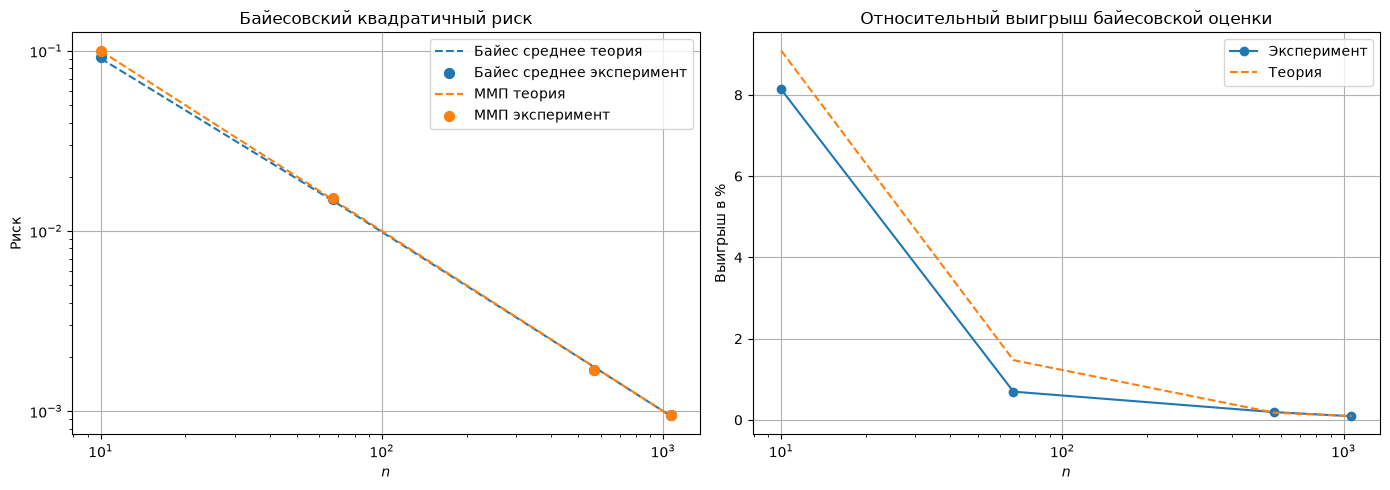

In [38]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

data = df_integrated.sort_values("n")
n_array = data["n"].to_numpy()

ax = axes[0]

for name, column, theory in [
    ("Байес среднее", "Байес MSE", "Байес теория"),
    ("ММП", "ММП MSE", "ММП теория")
]:
    line, = ax.plot(
        n_array,
        data[theory],
        "--",
        label=f"{name} теория"
    )

    ax.scatter(
        n_array,
        data[column],
        color=line.get_color(),
        s=50,
        zorder=3,
        label=f"{name} эксперимент"
    )

ax.set_title("Байесовский квадратичный риск")
ax.set_xlabel("$n$")
ax.set_ylabel("Риск")
ax.set_xscale("log")
ax.set_yscale("log")
ax.grid()
ax.legend()

ax = axes[1]

relative_gain = (
    (data["ММП MSE"] - data["Байес MSE"])
    / data["ММП MSE"] * 100
)

relative_gain_theory = (
    (data["ММП теория"] - data["Байес теория"])
    / data["ММП теория"] * 100
)

ax.plot(n_array, relative_gain, "o-", label="Эксперимент")
ax.plot(n_array, relative_gain_theory, "--", label="Теория")

ax.set_title("Относительный выигрыш байесовской оценки")
ax.set_xlabel("$n$")
ax.set_ylabel("Выигрыш в %")
ax.set_xscale("log")
ax.grid()
ax.legend()

plt.tight_layout()
plt.show()


## Вывод

Для пуассоновской выборки с гамма-априорным распределением получили сопряжённое апостериорное распределение

$$
\boxed{\theta\mid X\sim\Gamma(k+S;\lambda+n)}
$$

Байесовская оценка при квадратичной потере

$$
\boxed{\widehat\theta_{B2}=\frac{k+S}{\lambda+n}}
$$

При абсолютной потере получаем апостериорную медиану

$$
\boxed{\widehat\theta_{B1}=F^{-1}_{\Gamma(k+S;\lambda+n)}\left(\frac12\right)}
$$

Для предельной потери 0-1 с малым допуском получаем MAP

$$
\boxed{\widehat\theta_{\mathrm{MAP}}=\frac{\max\{k+S-1;0\}}{\lambda+n}}
$$

Для фиксированного допуска получили также точную байесовскую оценку через гиперболический тангенс

Оценка максимального правдоподобия

$$
\boxed{\widehat\theta_{\mathrm{ММП}}=\frac Sn}
$$

С ростом $n$ все рассмотренные оценки сближаются и их ошибки уменьшаются

На малых выборках влияние априорного распределения заметнее

Байесовская оценка оптимальна после усреднения риска по априорному распределению но не обязательно при каждом фиксированном $\theta$

Численные результаты согласуются с точными выражениями для смещения и MSE апостериорного среднего и ММП

В задаче о минимаксности при $\theta>0$ и обычных квадратичной абсолютной и потере 0-1 с допуском без дополнительных ограничений получаем вырожденный критерий

Поэтому нет содержательного единственного набора априорных гиперпараметров который можно выделить как минимаксный для данной постановки